# 1

### Nota: 9.25

En este proyecto, queremos que desarrolles un análisis de segmentación de clientes utilizando el algoritmo de Clustering KMeans, de la biblioteca Scikit-learn, para identificar grupos de clientes con patrones de compra similares. El análisis tendrás que realizarlo sobre el dataset 'Wholesale customers', y debes enforcarlo en cómo los clientes se agrupan según sus hábitos de compra en diversas categorías de productos.

In [114]:
import numpy as np
import pandas as pd
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns

work_dir = "../media/1_lab5/1/"
file_dir = "dataset.csv"
seed = 112211

df = pd.read_csv(work_dir + file_dir)

In [115]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [116]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [117]:
df.isna().sum().sum()

np.int64(0)

Todas las columnas son numéricas, y no hay ningún valor nulo

In [118]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


Hacemos un histograma para estudiar la distribución de los datos.

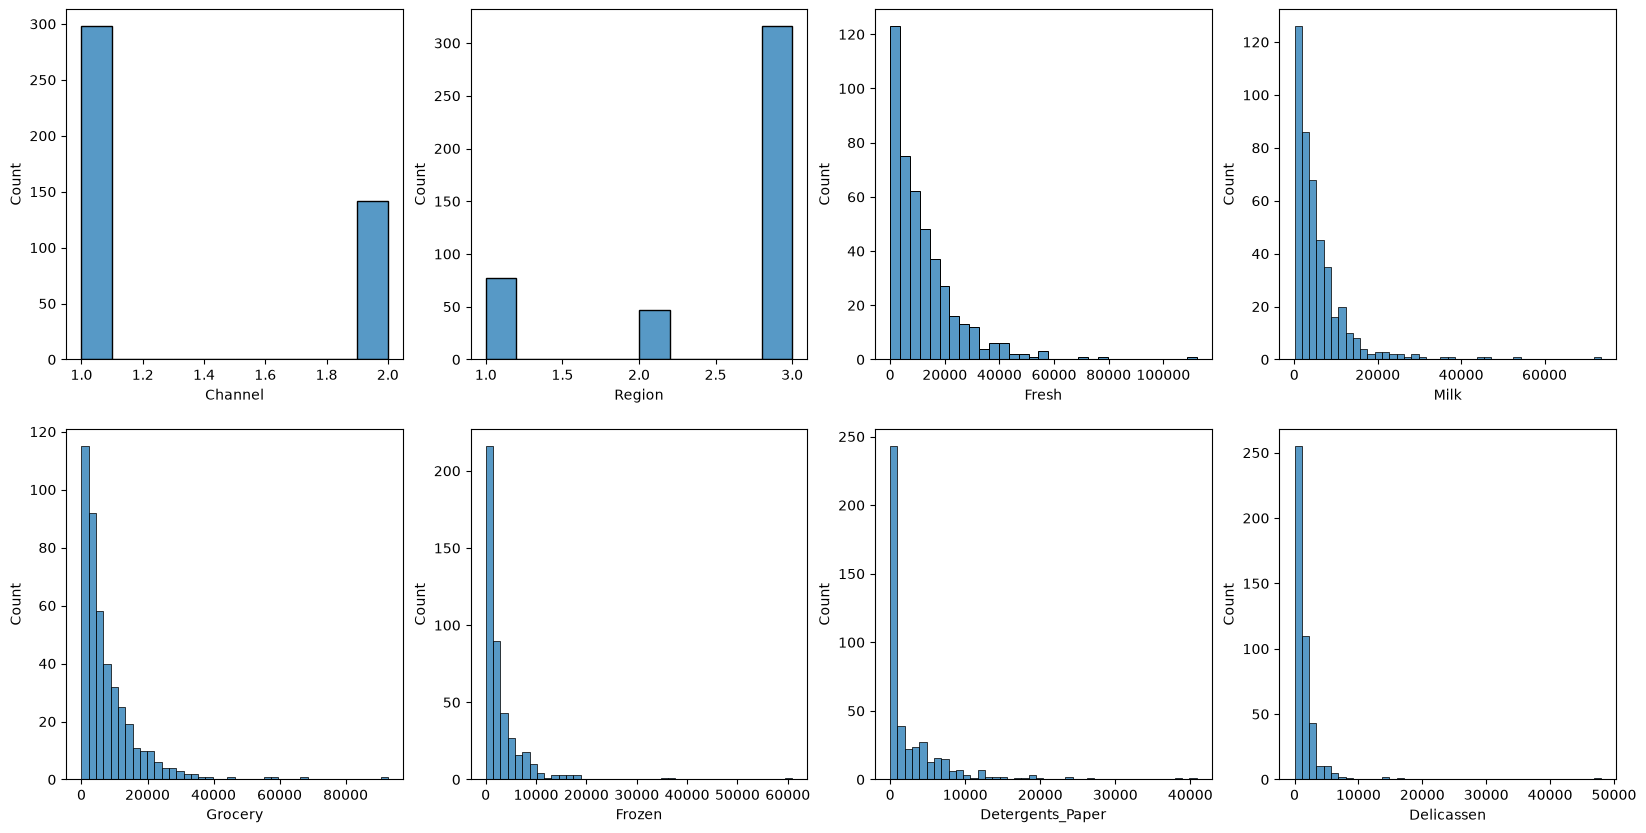

In [119]:
fig, axes = plt.subplots(2, 4, figsize = (20, 10))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.histplot(data = df, x = col, ax = axes[i])

plt.show()

A pesar de que las distribuciones no son simétricas, el ejercicio pide usar *StandardScaler*, por lo que estandarizamos.

In [120]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
scaled = sc.fit_transform(df)
df = pd.DataFrame(data = scaled, columns = df.columns)

In [121]:
df

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347
...,...,...,...,...,...,...,...,...
435,-0.690297,0.590668,1.401312,0.848446,0.850760,2.075222,-0.566831,0.241091
436,-0.690297,0.590668,2.155293,-0.592142,-0.757165,0.296561,-0.585519,0.291501
437,1.448652,0.590668,0.200326,1.314671,2.348386,-0.543380,2.511218,0.121456
438,-0.690297,0.590668,-0.135384,-0.517536,-0.602514,-0.419441,-0.569770,0.213046


Una vez normalizamos los datos, vamos a empezar con el KMeans. Entrenamos los modelos, y entre el método de silhouette y el codo, buscamos el valor óptimo para el número de clusters.

In [122]:
from sklearn.cluster import KMeans

k_space = np.arange(1, 11, 1)
model_per_k = []
wcss = []
s_scores = []


for k in k_space:
    model = KMeans(n_clusters = k, random_state = seed)
    model.fit(df)
    model_per_k.append(model)
    wcss.append(model.inertia_)
    if k != 1:
        s_scores.append(sk.metrics.silhouette_score(df, model.labels_))

### Método del Codo

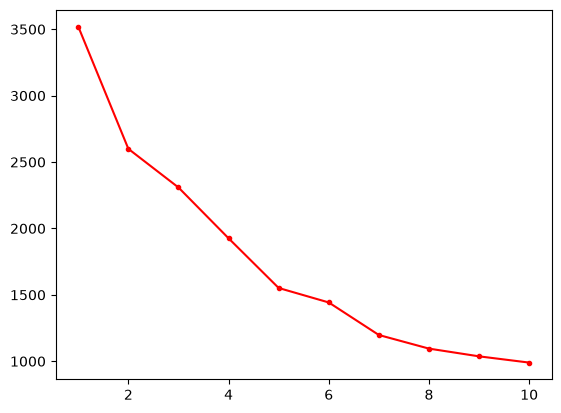

In [123]:
plt.plot(k_space, wcss, "r.")
plt.plot(k_space, wcss, "r-")
plt.show()

### Método de Silhouette

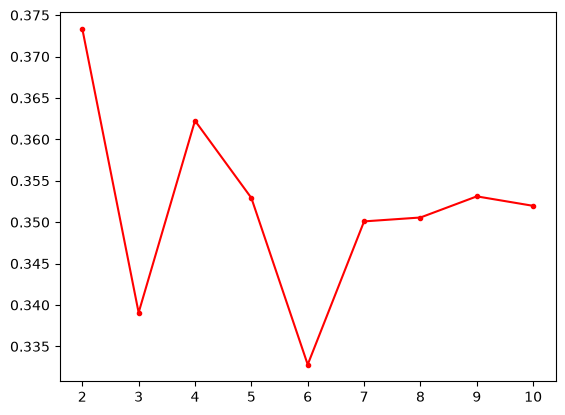

In [124]:
plt.plot(k_space[1:], s_scores, "r.")
plt.plot(k_space[1:], s_scores, "r-")
plt.show()

Con el método del codo se podría interpretar el valor $k = 5$, y con el silhouette, $k = 4$. Vamos a aplicar $k = 5$, y añadimos a cada cliente su etiqueta correspondiente.

In [125]:
km = model_per_k[4]
df["Cluster_Label"] = km.labels_

In [127]:
df

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster_Label
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339,4
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151,4
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293,4
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411,1
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347,4
...,...,...,...,...,...,...,...,...,...
435,-0.690297,0.590668,1.401312,0.848446,0.850760,2.075222,-0.566831,0.241091,1
436,-0.690297,0.590668,2.155293,-0.592142,-0.757165,0.296561,-0.585519,0.291501,1
437,1.448652,0.590668,0.200326,1.314671,2.348386,-0.543380,2.511218,0.121456,4
438,-0.690297,0.590668,-0.135384,-0.517536,-0.602514,-0.419441,-0.569770,0.213046,1


Para poder ver los resultados, vamos a aplicar un PCA, donde estudiaremos qué número de componentes es óptimo para enseñar la visualización.

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(random_state = seed)
df_pca = pd.DataFrame(pca.fit_transform(df.drop(columns = "Cluster_Label")), columns = [f"PCA_{n}" for n in range(1, pca.n_components_ + 1)])
df_pca["Cluster_Label"] = df["Cluster_Label"]
df_pca

,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7,PCA_8,Cluster_Label
0,0.843939,-0.515351,0.767632,0.044215,-0.446234,0.939441,0.654762,0.018102,4
1,1.062676,-0.484601,0.672975,-0.401372,-0.130458,0.867227,0.511022,0.077895,4
2,1.269141,0.682055,0.664095,-1.634953,-1.193813,1.078442,-0.203152,-0.254037,4
3,-1.056782,0.610821,0.505654,-0.196005,0.457855,-0.116959,-0.313804,0.054377,1
4,0.634030,0.974199,0.771209,-0.186374,-0.813877,1.505372,-0.160399,0.003763,4
...,...,...,...,...,...,...,...,...,...
435,0.222884,2.480505,0.360936,0.601036,1.109212,-0.364851,0.346184,0.860980,1
436,-1.290172,1.560397,0.756171,1.342401,-0.533462,0.205789,-0.242280,-0.226984,1
437,3.865149,-0.479854,0.525345,0.687132,0.108968,-0.280320,-0.575297,-0.089003,4
438,-1.097067,-0.069896,0.630128,-0.311821,-0.424792,-0.335170,-0.153744,-0.037308,1


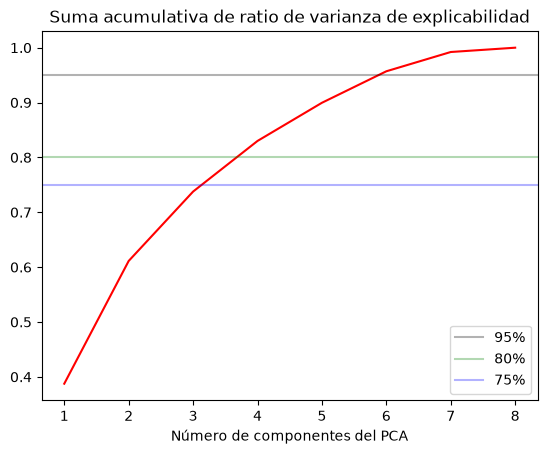

In [173]:
plt.plot(range(1, pca.n_components_ + 1), np.cumsum(pca.explained_variance_ratio_), "r-")
plt.axhline(0.95, color = "k", alpha = 0.3, label = "95%")
plt.axhline(0.8, color = "g", alpha = 0.3, label = "80%")
plt.axhline(0.75, color = "b", alpha = 0.3, label = "75%")
plt.title("Suma acumulativa de ratio de varianza de explicabilidad")
plt.xlabel("Número de componentes del PCA")
plt.legend()
plt.show()

Por motivos prácticos y una mejor visualización, vamos a considerar suficiente UN 75% de explicabilidad para poder así hacer un gráfico en 3 dimensiones

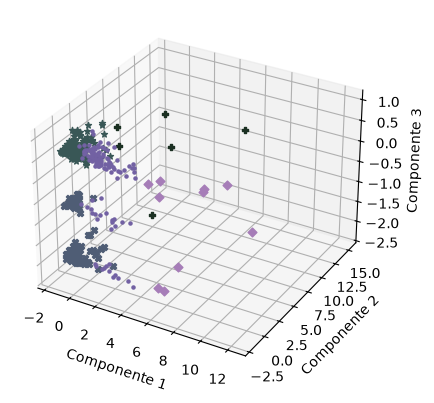

In [186]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
colormap = {
    0: "#1B3022",
    1: "#395756",
    2: "#4F5D75",
    3: "#A67DB8",
    4: "#7261A3"
}

markermap = {
    0: "P",
    1: "*",
    2: "X",
    3: "D",
    4: "."
}

for idx in range(len(df)):
    pca1 = df_pca.PCA_1.iloc[idx]
    pca2 = df_pca.PCA_2.iloc[idx]
    pca3 = df_pca.PCA_3.iloc[idx]
    label = df_pca.Cluster_Label.iloc[idx]

    ax.scatter(xs = pca1, ys = pca2, zs = pca3, marker = markermap[label], color = colormap[label])

ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.set_zlabel("Componente 3")
plt.show()

Veamos boxplots por cada cluster

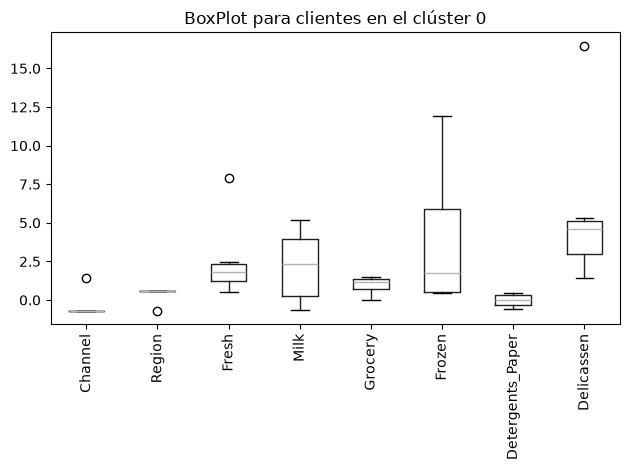

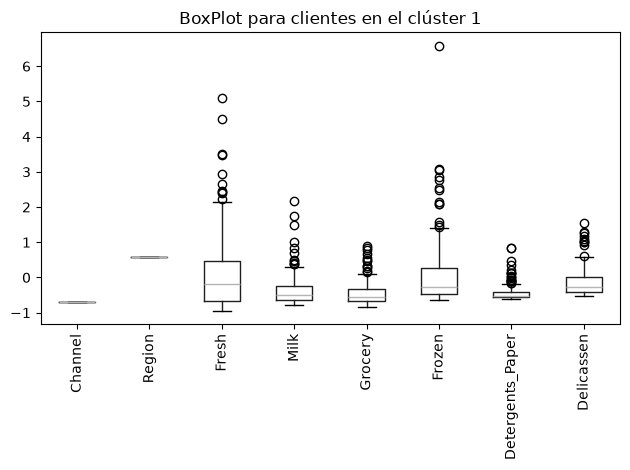

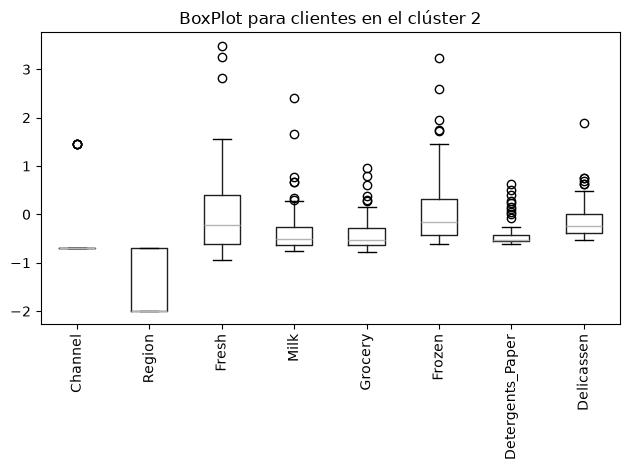

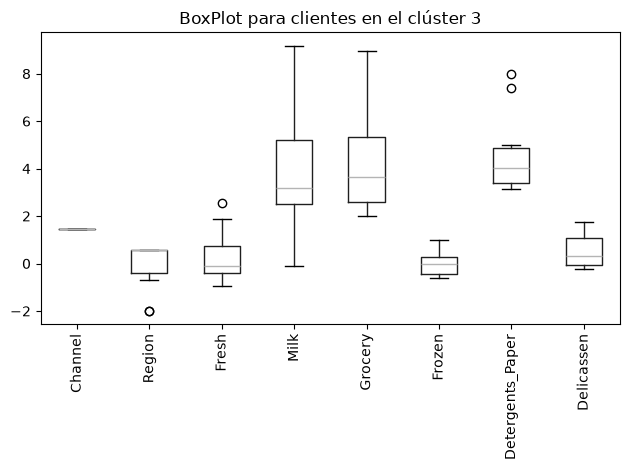

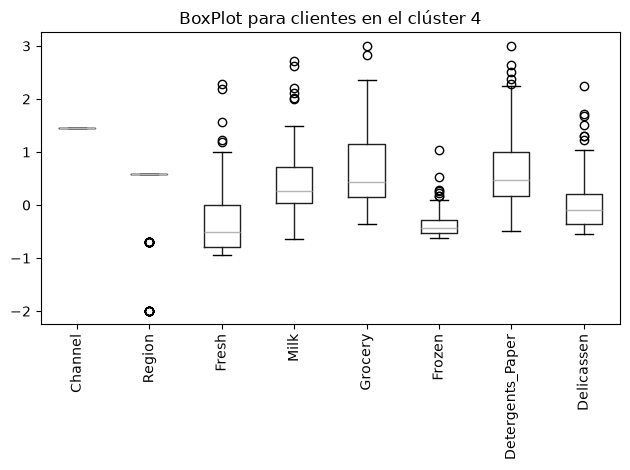

In [210]:
for label in range(5):
    df.drop(columns = "Cluster_Label").loc[df.Cluster_Label == label].boxplot(grid = False)
    plt.xticks(rotation = 90)
    plt.title(f"BoxPlot para clientes en el clúster {label}")
    plt.tight_layout()
    plt.show()

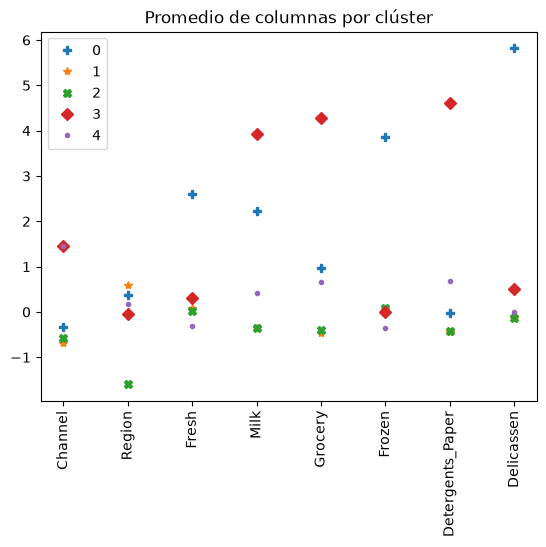

In [209]:
for label in range(5):
    plt.plot(df.drop(columns = "Cluster_Label").columns, df.loc[df.Cluster_Label == label].drop(columns = "Cluster_Label").mean(), markermap[label], label = label)

plt.title("Promedio de columnas por clúster")
plt.xticks(rotation = 90)
plt.legend()
plt.show()